# 04 | GBHeat — Local Authority heat-demand profiles

**Purpose.** Redistribute the **saved grid-level residential thermal heat-demand profiles** created by notebook **01** to 2021 GB Local Authorities using the existing `gbheatmodel.LA_heat_profiles` stock-informed methodology. Notebook **02** is not required: this notebook handles **thermal demand only**, not heating electricity.

**Choose:** one LA by name/code, several LAs, or `"all"`. Each selected LA receives a half-hourly CSV containing its original heating-technology columns (kWh per half-hour). The notebook also generates annual summaries, optional maps and **conservation diagnostics**.

**Scientific implementation:** `gbheatmodel.LA_heat_profiles.read_hd_profiles_from_folder`, `build_grid_annual_heat_map`, `prepare_fes_stock_index`, `redistribute_grid_heat_to_las`, and `build_la_half_hourly_profiles_by_technology`. This notebook does **not** replace those package functions with area-only weighting.

**Important:** weights are calculated against *all* intersecting LAs before filtering. Selecting one LA must not cause the entire demand of intersecting grids to be reassigned to that LA.

**Execution:** Run notebook 01 first to produce the saved heat profiles for the same scenario; then run all cells here, from the top, in a clean kernel. No national demand is regenerated.

## 1. User settings
Use the same four model assumptions as notebook 01. Set `LA_SELECTION` to one name/code, a list, or `"all"`.

In [1]:
weather_year = 2010
future_year = 2050
FES_year = "2022"
FES_scenario = "LW"

# Examples:
# LA_SELECTION = "Perth and Kinross"
# LA_SELECTION = ["Perth and Kinross", "City of Edinburgh"]
# LA_SELECTION = ["S12000048", "S12000036"]
LA_SELECTION = ["Perth and Kinross"]

# Preserve your existing package methodology:
# "fes_stock" = total residential heating stock across intersecting LAs
# "fes_stock_area" = FES stock weighted by fraction of each LA's area in the grid
method = "fes_stock_area"

SAVE_OUTPUTS = True
SHOW_PLOTS = True
PLOT_SELECTED_MAX = 10  # prevents hundreds of plots when selecting "all"
SAVE_LA_MAP = True
FIGURE_DPI = 300

# Strict conservation verifies *all* LAs against the complete GB grid demand.
# Fails with diagnostics if grid heat is not fully redistributed.
STRICT_CONSERVATION = True
RTOL = 1e-8
ATOL_KWH = 1e-5

## 2. Imports and paths
All paths are resolved using `gbheatmodel.path`. This works on your local Windows machine and after cloning the GitHub repository; personal absolute paths are not embedded. Unlike the original LA notebook, the output folder includes **weather year**, **FES version**, **scenario**, **future year** and **allocation method**.

In [2]:
from pathlib import Path
import re
import json
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display

from gbheatmodel.path import path_in_data
from gbheatmodel import FES_heat_supply_data
from gbheatmodel.FES_shapefile_LAs_matching import match_FES_and_shapefile_LAs
from gbheatmodel.LA_heat_profiles import (
    read_hd_profiles_from_folder,
    build_grid_annual_heat_map,
    prepare_fes_stock_index,
    redistribute_grid_heat_to_las,
    build_la_half_hourly_profiles_by_technology,
)

if method not in {"fes_stock", "fes_stock_area"}:
    raise ValueError("method must be 'fes_stock' or 'fes_stock_area'")

RUN_ID = f"{weather_year}_{FES_year}_{FES_scenario}_{future_year}"
PROFILE_DIR = Path(path_in_data("outputs", "heating_profiles", RUN_ID))
LA_OUTPUT_DIR = Path(path_in_data("outputs", "LA_heat_profiles", RUN_ID, method))
FIGURE_DIR = Path(path_in_data("outputs", "figures", RUN_ID, "04_Local_Authority_Heat_Demand", method))
GRID_FILE = Path(path_in_data("UK_Atlite_Grid_sq.gpkg"))
LA_FILE = Path(path_in_data("LAs_shapefile_2021", "LAD_DEC_2021_GB_BFC.shp"))

for input_path in (PROFILE_DIR, GRID_FILE, LA_FILE):
    if not input_path.exists():
        raise FileNotFoundError(f"Missing required input: {input_path}")

print(f"GBHeat run: {RUN_ID}")
print(f"Allocation method: {method}")
print(f"Grid profiles: {PROFILE_DIR}")
print(f"LA profiles: {LA_OUTPUT_DIR}")
print(f"Figures: {FIGURE_DIR}")

GBHeat run: 2010_2022_LW_2050
Allocation method: fes_stock_area
Grid profiles: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050
LA profiles: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\LA_heat_profiles\2010_2022_LW_2050\fes_stock_area
Figures: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\04_Local_Authority_Heat_Demand\fes_stock_area


## 3. Load saved grid heat profiles and spatial boundaries
Demand values are **kWh per 30-minute interval**. Validate consistent technology columns, timestamps and finite values before redistributing. Loading the full GB model is necessary for a correct national conservation check and because allocation is calculated using all LA overlaps.

In [3]:
profiles = read_hd_profiles_from_folder(PROFILE_DIR)
if not profiles:
    raise ValueError(f"No grid-level heat profiles found in {PROFILE_DIR}")

reference_id, reference = next(iter(profiles.items()))
reference_index = pd.to_datetime(reference.index, errors="raise")
reference_cols = list(reference.columns)
if not reference_index.is_unique or not reference_index.is_monotonic_increasing:
    raise ValueError("Grid-profile timestamps must be unique and sorted")
expected_steps = (366 if pd.Timestamp(f"{future_year}-12-31").is_leap_year else 365) * 48
expected_index = pd.date_range(f"{future_year}-01-01", periods=expected_steps, freq="30min")
if not reference_index.equals(expected_index):
    raise ValueError("Grid-profile timestamps do not match the complete half-hourly target year")

for grid, frame in profiles.items():
    frame.index = pd.to_datetime(frame.index, errors="raise")
    if not frame.index.equals(reference_index):
        raise ValueError(f"Grid {grid}: inconsistent half-hourly time index")
    if list(frame.columns) != reference_cols:
        raise ValueError(f"Grid {grid}: inconsistent technology columns")
    for column in reference_cols:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"Grid {grid}: missing or non-finite heat-demand values")
    if (frame.to_numpy(dtype=float) < -ATOL_KWH).any():
        raise ValueError(f"Grid {grid}: negative thermal demand")

print(f"Loaded {len(profiles)} grid profiles; {len(reference_cols)} technologies; "
      f"{len(reference_index)} half-hourly timesteps")

grid_gdf = gpd.read_file(GRID_FILE)
la_gdf = gpd.read_file(LA_FILE)
required = {"LAD21CD", "LAD21NM", "geometry"}
if not required.issubset(la_gdf.columns):
    raise ValueError(f"LA boundaries missing columns: {required - set(la_gdf.columns)}")
if la_gdf["LAD21CD"].duplicated().any():
    raise ValueError("LAD21CD must uniquely identify each LA")
if la_gdf.crs is None or grid_gdf.crs is None:
    raise ValueError("LA and grid geometry need defined CRSs")

grid_map = build_grid_annual_heat_map(profiles=profiles, grid_gdf=grid_gdf)
print(f"Loaded {len(la_gdf)} LAD 2021 boundaries")

Loaded 738 grid profiles; 14 technologies; 17520 half-hourly timesteps


Cannot find header.dxf (GDAL_DATA is not defined)


Loaded 363 LAD 2021 boundaries


## 4. Resolve LA selection
Case-insensitive **exact** matching of 2021 LA names or LAD codes. Unknown and ambiguous matches stop execution rather than silently choosing an authority.

In [4]:
def resolve_la_selection(selection, boundaries):
    choices = boundaries[["LAD21CD", "LAD21NM"]].drop_duplicates().copy()
    choices["LAD21CD"] = choices["LAD21CD"].astype(str).str.strip()
    choices["LAD21NM"] = choices["LAD21NM"].astype(str).str.strip()
    if isinstance(selection, str) and selection.strip().casefold() == "all":
        return choices.sort_values("LAD21NM").reset_index(drop=True), True
    requested = [selection] if isinstance(selection, str) else list(selection)
    if not requested:
        raise ValueError('Empty LA selection: provide one LA, a list, or "all"')
    matches = []
    for item in requested:
        key = str(item).strip().casefold()
        rows = choices[
            choices["LAD21CD"].str.casefold().eq(key)
            | choices["LAD21NM"].str.casefold().eq(key)
        ]
        if len(rows) != 1:
            examples = choices["LAD21NM"].head(8).tolist()
            raise ValueError(
                f"LA {item!r} has {len(rows)} exact matches in LAD 2021. "
                f"Use a unique LAD21NM or LAD21CD. Examples: {examples}"
            )
        matches.append(rows.iloc[0])
    return (pd.DataFrame(matches).drop_duplicates("LAD21CD")
            .sort_values("LAD21NM").reset_index(drop=True)), False

selected_las, ALL_SELECTED = resolve_la_selection(LA_SELECTION, la_gdf)
selected_codes = set(selected_las["LAD21CD"])
print(f"Selected {len(selected_las)} / {len(la_gdf)} Local Authorities")
display(selected_las.head(20))

Selected 1 / 363 Local Authorities


,LAD21CD,LAD21NM
0,S12000048,Perth and Kinross


## 5. FES stock-informed redistribution (existing GBHeat implementation)
This reproduces the original `LA_HD_Profile.ipynb` sequence. **Do not filter `la_gdf`, FES stock, or overlaps to selected LAs here:** that would alter the denominators and could overallocate each selected LA.

In [5]:
fes_raw = FES_heat_supply_data.year_FES_heat_supply(
    year=future_year, FES=FES_year, scenario=FES_scenario,
)
fes_matched = match_FES_and_shapefile_LAs(
    df=fes_raw, future_year=future_year, FES=FES_year, scenario=FES_scenario,
)
fes_stock_index, tech_stock_cols = prepare_fes_stock_index(fes_matched)

# Use *all* grid squares, all LAD boundaries and all FES stock to determine weights.
overlay_la, la_demand, la_map = redistribute_grid_heat_to_las(
    grid_map=grid_map,
    la_gdf=la_gdf,
    fes_stock_index=fes_stock_index,
    method=method,
)

# Existing GBHeat method builds all LA technology profiles from the full overlay.
la_profiles = build_la_half_hourly_profiles_by_technology(
    profiles=profiles,
    overlay_la=overlay_la,
)
print(f"Generated {len(la_profiles)} LA profiles using '{method}'")
print(f"Matched FES authorities: {len(fes_stock_index)}")
print(f"FES heating-stock fields: {len(tech_stock_cols)}")

Generated 363 LA profiles using 'fes_stock_area'
Matched FES authorities: 363
FES heating-stock fields: 29


In [6]:
# ============================================================
# Validate Local Authority coverage (LAD 2021)
# ============================================================

expected_las = 363

# Number of unique LAs in the 2021 boundary dataset
actual_boundaries = la_gdf["LAD21CD"].nunique()

# Number of LAs with generated heat-demand profiles
actual_profiles = len(la_profiles)

print(f"Expected LAs: {expected_las}")
print(f"LA boundaries: {actual_boundaries}")
print(f"Generated LA profiles: {actual_profiles}")

assert actual_boundaries == expected_las, (
    f"Expected {expected_las} LAD 2021 boundaries, "
    f"but found {actual_boundaries}"
)

# Verify that every boundary LA has a generated profile
boundary_codes = set(la_gdf["LAD21CD"].astype(str))
profile_codes = set(map(str, la_profiles.keys()))

missing_las = sorted(boundary_codes - profile_codes)
unexpected_las = sorted(profile_codes - boundary_codes)

assert not missing_las and not unexpected_las, (
    f"Missing LA profiles: {missing_las}\n"
    f"Unexpected LA profiles: {unexpected_las}"
)

print(
    f"✓ All {actual_boundaries} Local Authorities "
    "have generated heat-demand profiles."
)

Expected LAs: 363
LA boundaries: 363
Generated LA profiles: 363
✓ All 363 Local Authorities have generated heat-demand profiles.


## 6. Detailed conservation diagnostics — *before* LA filtering
For every technology and timestep, verify **sum of complete LA heat demand = sum of complete grid heat demand**. Capture any unallocated demand instead of renormalising or silently discarding it. Spatial weights should sum to one for every modelled grid cell.

**Selected subset:** the selected-LA total will naturally be lower than the GB total when fewer than all LAs are requested. This is *not* an allocation error.

In [7]:
def numeric_la_frame(raw, la_code):
    frame = raw.drop(columns=["LAD21NM"], errors="ignore").copy()
    frame.index = pd.to_datetime(frame.index, errors="raise")
    if frame.index.has_duplicates or not frame.index.equals(reference_index):
        raise ValueError(f"LA {la_code}: timestamp mismatch")
    if set(frame.columns) != set(reference_cols):
        raise ValueError(f"LA {la_code}: expected technology columns {reference_cols}, "
                         f"found {list(frame.columns)}")
    frame = frame[reference_cols].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"LA {la_code}: NaN/inf values")
    return frame

numeric_la_profiles = {str(code): numeric_la_frame(df, code)
                       for code, df in la_profiles.items()}

# Independently accumulate both spatial resolutions by matching timestamp and technology.
grid_totals = pd.DataFrame(0.0, index=reference_index, columns=reference_cols)
for df in profiles.values():
    grid_totals += df[reference_cols].astype(float)

la_totals = pd.DataFrame(0.0, index=reference_index, columns=reference_cols)
for df in numeric_la_profiles.values():
    la_totals += df

unallocated = grid_totals - la_totals  # negative = overallocation
annual_diagnostic = pd.DataFrame({
    "Technology": reference_cols,
    "Grid_Annual_kWh": grid_totals.sum().to_numpy(),
    "All_LA_Annual_kWh": la_totals.sum().to_numpy(),
    "Difference_Grid_minus_LAs_kWh": unallocated.sum().to_numpy(),
    "Max_Absolute_Halfhour_Difference_kWh": unallocated.abs().max().to_numpy(),
})
annual_diagnostic["Relative_Annual_Difference"] = (
    annual_diagnostic["Difference_Grid_minus_LAs_kWh"].abs()
    / annual_diagnostic["Grid_Annual_kWh"].abs().clip(lower=1)
)

full_conserved = np.allclose(
    grid_totals.to_numpy(), la_totals.to_numpy(), rtol=RTOL, atol=ATOL_KWH
)
print(f"GB grid total: {grid_totals.to_numpy().sum()/1e9:.6f} TWh")
print(f"ALL LA total: {la_totals.to_numpy().sum()/1e9:.6f} TWh")
print(f"Grid minus ALL LAs: {unallocated.to_numpy().sum()/1e6:.9f} GWh")
print(f"Conserved by technology AND timestep: {full_conserved}")
display(annual_diagnostic)

# Grid-level spatial weight audit; expect sum = 1 for all profiles (within tolerance).
weight_candidates = ["Stock_Area_Redistribution_Factor", "Stock_Redistribution_Factor",
                     "Redistribution_Factor", "weight", "Weight"]
weight_col = next((x for x in weight_candidates if x in overlay_la.columns), None)
if weight_col is None:
    inferred = [x for x in overlay_la.columns if "factor" in x.lower() and "redistribution" in x.lower()]
    weight_col = inferred[0] if len(inferred) == 1 else None
if "Grid_ID" not in overlay_la.columns or weight_col is None:
    raise ValueError("Cannot audit redistribution weights: inspect overlay_la columns "
                     f"{overlay_la.columns.tolist()}. No assumed weights were substituted.")

weight_sums = overlay_la.groupby("Grid_ID")[weight_col].sum()
weight_audit = pd.DataFrame({"Grid_ID": list(profiles)})
weight_audit["Weight_Sum"] = weight_audit["Grid_ID"].map(weight_sums).fillna(0.0)
weight_audit["Missing_Or_Excess_Weight"] = 1 - weight_audit["Weight_Sum"]
missing_grid_weights = weight_audit.loc[
    ~np.isclose(weight_audit["Weight_Sum"], 1.0, atol=1e-8, rtol=1e-8)
]
if len(missing_grid_weights):
    print(f"WARNING: {len(missing_grid_weights)} grid cells have incomplete/excess stock weights")
    display(missing_grid_weights.head(20))
else:
    print("All grid cells have weights summing to one")

# Export audit data even if strict validation fails.
if SAVE_OUTPUTS:
    LA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    annual_diagnostic.to_csv(LA_OUTPUT_DIR / "conservation_by_technology.csv", index=False)
    unallocated.to_csv(LA_OUTPUT_DIR / "unallocated_demand_by_timestep_and_technology_kWh.csv",
                       index_label="timestamp")
    weight_audit.to_csv(LA_OUTPUT_DIR / "grid_weight_audit.csv", index=False)

if STRICT_CONSERVATION and (not full_conserved or len(missing_grid_weights)):
    raise AssertionError(
        "LA redistribution did not fully conserve grid heat demand. "
        f"Inspect {LA_OUTPUT_DIR}/conservation_by_technology.csv, "
        "unallocated_demand_by_timestep_and_technology_kWh.csv and grid_weight_audit.csv."
    )

GB grid total: 222.766234 TWh
ALL LA total: 222.766234 TWh
Grid minus ALL LAs: 0.000000000 GWh
Conserved by technology AND timestep: True


,Technology,Grid_Annual_kWh,All_LA_Annual_kWh,Difference_Grid_minus_LAs_kWh,Max_Absolute_Halfhour_Difference_kWh,Relative_Annual_Difference
0,ASHP,4.303737e+10,4.303737e+10,2.676388e-07,2.328306e-08,6.218755e-18
1,GSHP,5.198304e+10,5.198304e+10,-4.213653e-07,2.700835e-08,8.105821e-18
2,Gas boiler,2.180203e+05,2.180203e+05,2.394973e-12,1.136868e-13,1.098509e-17
3,Electric storage,1.123064e+10,1.123064e+10,1.653680e-07,5.355105e-09,1.472471e-17
4,Hybrid (ASHP + Electric resistive),3.155075e+10,3.155075e+10,-6.587943e-07,2.421439e-08,2.088047e-17
5,Oil boiler,3.305779e+01,3.305779e+01,2.866088e-16,1.561251e-17,8.669932e-18
6,Biomass boiler,3.101398e+09,3.101398e+09,2.533852e-08,1.979060e-09,8.170032e-18
7,BioLPG boiler,6.865908e+09,6.865908e+09,5.804031e-08,5.122274e-09,8.453407e-18
8,Community,4.840458e+06,4.840458e+06,-4.593659e-12,3.069545e-12,9.490133e-19
9,Hybrid (ASHP + BioLPG boiler),2.087299e+09,2.087299e+09,-2.668821e-08,1.571607e-09,1.278600e-17


All grid cells have weights summing to one


## 7. Extract one / several / all selected LAs and export
Only **after** the full all-LA redistribution and its diagnostics do we select output profiles. This preserves the correct stock weights. CSV filenames use unambiguous LAD codes; a name/code lookup and run manifest provide provenance. Outputs are designed so notebook 03 can read the selected LA profiles by pointing `LA_PROFILE_FOLDER` to the `profiles/` directory.

**National reconciliation:** only an `"all"` selection should match GB totals. For subsets, save their energy share without asserting national conservation.

In [8]:
selected_profiles = {code: numeric_la_profiles[code] for code in selected_las["LAD21CD"]
                     if code in numeric_la_profiles}
missing_selected = sorted(selected_codes - set(selected_profiles))
if missing_selected:
    raise ValueError("Selected LAs lack a generated stock-informed profile: "
                     f"{missing_selected}. No zero profile is fabricated.")

selected_records = []
for entry in selected_las.itertuples(index=False):
    df = selected_profiles[entry.LAD21CD]
    series = df.sum(axis=1)
    selected_records.append({
        "LAD21CD": entry.LAD21CD,
        "LAD21NM": entry.LAD21NM,
        "Annual_Heat_GWh": series.sum() / 1e6,
        "Local_Peak_MW": series.max() * 2 / 1000,
        "Local_Peak_Timestamp": series.idxmax(),
    })
selected_summary = pd.DataFrame(selected_records).sort_values("Annual_Heat_GWh", ascending=False)
selected_total_kwh = sum(df.to_numpy().sum() for df in selected_profiles.values())
all_grid_total_kwh = grid_totals.to_numpy().sum()
print(f"Selected authorities: {len(selected_profiles)}")
print(f"Selected annual demand: {selected_total_kwh/1e9:.6f} TWh")
print(f"Share of GB grid thermal demand: {100*selected_total_kwh/all_grid_total_kwh:.4f}%")
display(selected_summary.head(20))

if SAVE_OUTPUTS:
    profile_output_dir = LA_OUTPUT_DIR / "profiles"
    profile_output_dir.mkdir(parents=True, exist_ok=True)
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    for code, frame in selected_profiles.items():
        frame.to_csv(profile_output_dir / f"LA_heat_profile_{code}.csv", index_label="timestamp")
    selected_summary.to_csv(LA_OUTPUT_DIR / "selected_LA_annual_peak_summary.csv", index=False)
    selected_las.to_csv(LA_OUTPUT_DIR / "selected_LA_lookup.csv", index=False)
    manifest = {
        "weather_year": weather_year,
        "future_year": future_year,
        "FES_year": str(FES_year),
        "FES_scenario": FES_scenario,
        "allocation_method": method,
        "selection": "all" if ALL_SELECTED else list(selected_las["LAD21CD"]),
        "number_selected": len(selected_profiles),
        "number_all_profiles": len(numeric_la_profiles),
        "units": "kWh per half-hour",
        "all_LA_conservation_passed": bool(full_conserved and not len(missing_grid_weights)),
        "gb_grid_annual_kWh": float(all_grid_total_kwh),
        "selected_LA_annual_kWh": float(selected_total_kwh),
        "source_grid_profile_dir": str(PROFILE_DIR),
        "la_profile_dir": str(profile_output_dir),
    }
    (LA_OUTPUT_DIR / "run_manifest.json").write_text(
        json.dumps(manifest, indent=2), encoding="utf-8"
    )
    print(f"Saved selected LA CSVs to: {profile_output_dir}")

Selected authorities: 1
Selected annual demand: 0.637619 TWh
Share of GB grid thermal demand: 0.2862%


,LAD21CD,LAD21NM,Annual_Heat_GWh,Local_Peak_MW,Local_Peak_Timestamp
0,S12000048,Perth and Kinross,637.61857,245.890792,2050-12-07 07:30:00


Saved selected LA CSVs to: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\LA_heat_profiles\2010_2022_LW_2050\fes_stock_area\profiles


## 8. Optional demand profiles and annual LA map
For selections of up to `PLOT_SELECTED_MAX` authorities, save an annual thermal demand bar chart and individual half-hourly time series (MW). The geographic map uses the **full all-LA** annual redistribution; its title is not affected by the selected subset. Figures are stored separately in `data/outputs/figures/<run>/04_Local_Authority_Heat_Demand/<method>/`.

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\04_Local_Authority_Heat_Demand\fes_stock_area\LA_thermal_profile_S12000048.png


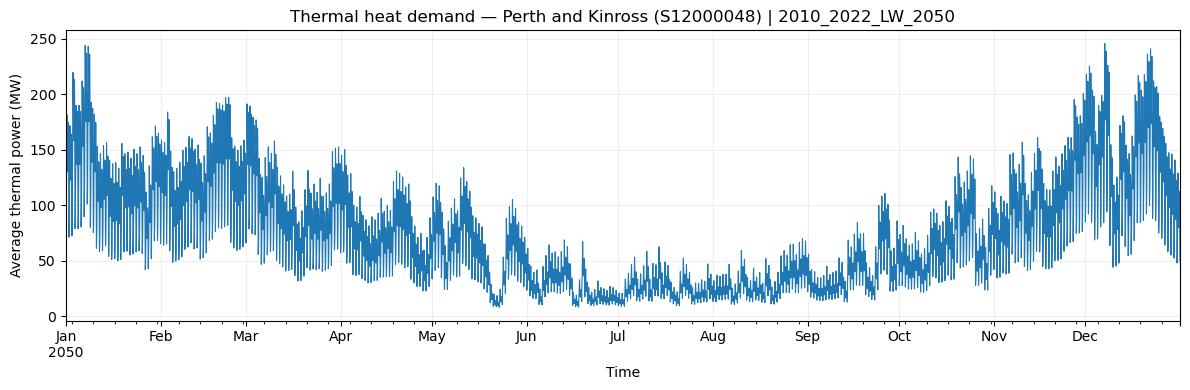

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\04_Local_Authority_Heat_Demand\fes_stock_area\LA_annual_thermal_heat_demand_map.png


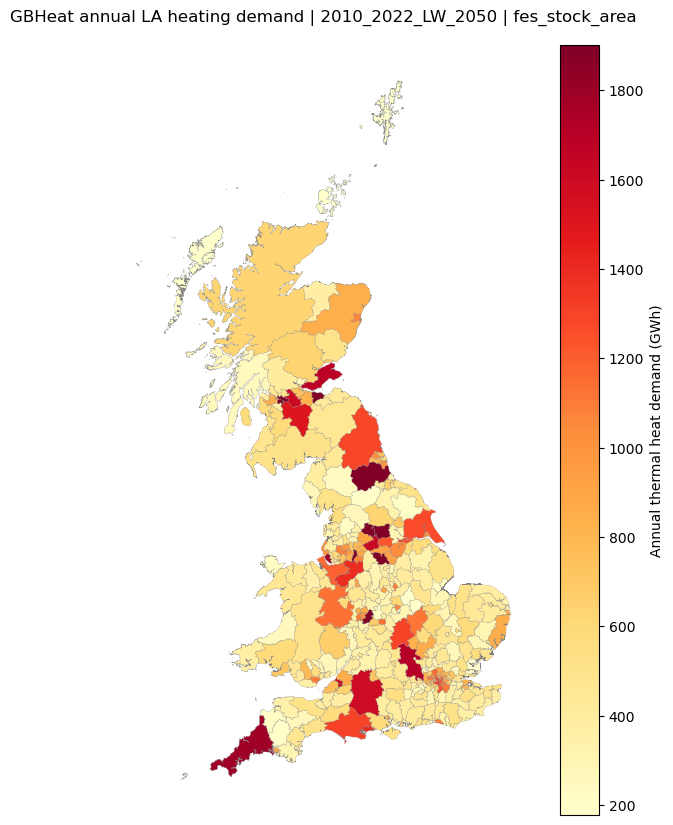

Notebook 04 completed. All-LA conservation diagnostics and selected outputs are available above.


In [9]:
def finish_plot(fig, name):
    if SAVE_OUTPUTS:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        target = FIGURE_DIR / name
        fig.savefig(target, dpi=FIGURE_DPI, bbox_inches="tight")
        print("Saved:", target)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

if PLOT_SELECTED_MAX > 0:
    for entry in selected_las.head(PLOT_SELECTED_MAX).itertuples(index=False):
        df = selected_profiles[entry.LAD21CD]
        fig, ax = plt.subplots(figsize=(12, 4))
        (df.sum(axis=1) * 2 / 1000).plot(ax=ax, linewidth=0.8)
        ax.set(title=f"Thermal heat demand — {entry.LAD21NM} ({entry.LAD21CD}) | {RUN_ID}",
               xlabel="Time", ylabel="Average thermal power (MW)")
        ax.grid(alpha=0.2)
        fig.tight_layout()
        finish_plot(fig, f"LA_thermal_profile_{entry.LAD21CD}.png")

if SAVE_LA_MAP:
    if "Allocated_Heat_GWh" not in la_map.columns:
        raise ValueError("Expected Allocated_Heat_GWh in package LA map")
    fig, ax = plt.subplots(figsize=(8, 10))
    values = la_map["Allocated_Heat_GWh"].dropna()
    if values.empty:
        raise ValueError("No LA annual demand values available for map")
    la_map.plot(column="Allocated_Heat_GWh", cmap="YlOrRd", ax=ax,
                edgecolor="grey", linewidth=0.15, legend=True,
                vmin=values.quantile(0.02), vmax=values.quantile(0.98),
                legend_kwds={"label": "Annual thermal heat demand (GWh)"},
                missing_kwds={"color": "white"})
    ax.set(title=f"GBHeat annual LA heating demand | {RUN_ID} | {method}")
    ax.axis("off")
    finish_plot(fig, "LA_annual_thermal_heat_demand_map.png")

print("Notebook 04 completed. All-LA conservation diagnostics and selected outputs are available above.")

## 9. Scientific interpretation, compatibility and limitations

- **Reference workflow:** notebooks 01 and 02 define the scenario settings; this notebook uses the *saved* thermal outputs from 01. It does not regenerate heat, COP, or electricity demand.
- **Allocation:** the functions in `gbheatmodel.LA_heat_profiles` provide the two existing FES-stock-informed methods. `fes_stock_area` apportions FES stock across LA/grid intersections by area before normalising within each grid. No equal-area-only fallback is used.
- **Not an exact inverse:** stock-weighted redistribution of grid demand is an LA-level estimate and does not necessarily reconstruct the original LA contribution to each gridded profile.
- **Selection:** filtering only final LA profiles does not change stock weights. If one/two LAs are selected, their totals do not equal GB totals by design.
- **Conservation:** all-LA, all-technology, all-timestep differences and any grid with non-unit weight sum are exported; no missing demand is silently forced to zero. A strict failure halts output export after audit files are saved.
- **Units:** each CSV represents *thermal energy* in **kWh per 30 minutes**. Average **MW** = 2 × kWh / 1,000. Annual **GWh** = ΣkWh / 1,000,000.
- **Notebook 03:** To inspect LA demand there, set `LA_PROFILE_FOLDER` to the `profiles` directory created by this notebook. If only a subset was exported, GB/LA totals need not agree.
- **Output provenance:** `run_manifest.json` records the four scenario assumptions, allocation method and chosen LA codes. Repeating a run with the same settings overwrites the corresponding files; change the destination or archive the previous results if needed.
- **Prerequisite:** requires the existing `gbheatmodel.LA_heat_profiles` package module and FES/LA/grid source datasets. Python syntax has been checked, but local runtime testing against the complete GBHeat data is still required.